## Drilling Simulator based on DrillPyze

Step 1: Import necessary modules

To generate updated docs, run:

sphinx-apidoc -o docs src/DrillPyze/

make html

In [1]:
from DrillPyze import well, drillstring, statics, dynamics
import numpy as np
import matplotlib.pyplot as plt
from drawnow import drawnow

Step 2: load the wellpath

In [2]:
well1 = well.wellbore({'xlsx':'../data/survey.xlsx'}, 1000, 5)
well1.get_trajectory().plot(style={'color': 'dls', 'size': 5}).show()

Step 3: load the BHA

In [3]:
bha1 = drillstring.BHA('BHA 1', '../data/bha.xlsx')
bha1.data

,Component,Length,OD,ID,Weight
0,DP,30,4.5,2.5,NaN
1,HWDP,30,5.5,2.5,NaN
2,DC,30,6.0,2.0,NaN
3,Stab,5,8.0,2.0,NaN
4,DC,30,6.0,2.0,NaN
5,Tool,15,6.0,2.0,NaN
6,DC,30,6.0,2.0,NaN
7,Bit,1,8.0,2.0,NaN


Discretize the drillstring

In [4]:
bha1.discretize(10, 9000)
well1.get_interpolated(bha1.x)

Step 4: Compute the normal forces

In [5]:
(Ft, Ft_pu, Ft_so, Fn, M) = statics.normal_forces(well1, bha1)

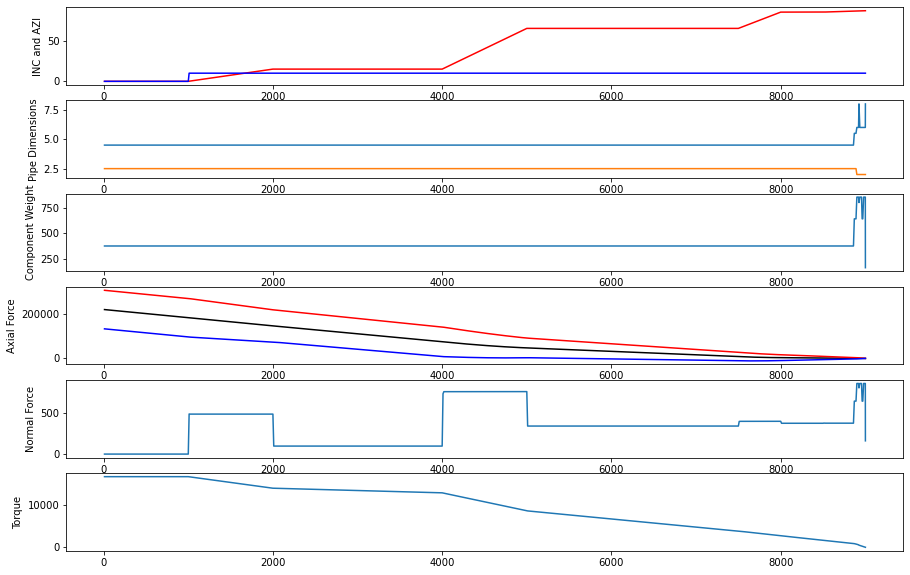

In [6]:
fig = plt.figure(figsize=[15,10])
plt.subplot(6,1,1)
plt.plot(well1.md,well1.inc, 'r')
plt.plot(well1.md,well1.azi, 'b')
plt.ylabel('INC and AZI')

plt.subplot(6,1,2)
plt.plot(well1.md,bha1.OD)
plt.plot(well1.md,bha1.ID)
plt.ylabel('Pipe Dimensions')

plt.subplot(6,1,3)
plt.plot(well1.md,bha1.w)
plt.ylabel('Component Weight')

plt.subplot(6,1,4)
plt.plot(well1.md, Ft, 'k')
plt.plot(well1.md, Ft_pu, 'r')
plt.plot(well1.md, Ft_so, 'b')
plt.ylabel('Axial Force')

plt.subplot(6,1,5)
plt.plot(well1.md, Fn)
plt.ylabel('Normal Force')

plt.subplot(6,1,6)
plt.plot(well1.md, M)
plt.ylabel('Torque')

plt.show()

Step 5: Create and run a Simulation

In [12]:
%matplotlib notebook

sim = dynamics.Simulation('Test Simulation', well1, bha1)
sim.initialize_simulation(7000, 100)
sim.step(0.1)


plt.figure()
fig, ax = plt.subplots()
ln, = ax.plot([], [], 'g-')

for i in range (0,20):
    sim.step(0.1, 60)

    x = bha1.x
    y = sim.omega[:,2]
    X, Y = ln.get_xdata(), ln.get_ydata()
    ln.set_data(np.r_[X, x], np.r_[Y, y])
    fig.canvas.draw()
    fig.canvas.flush_events()

100


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

100


<IPython.core.display.Javascript object>

... (30 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/Users/roman/opt/anaconda3/lib/python3.9/site-packages/IPython/core/interactiveshell.py", line 3369, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/p8/_kn3lrj14fv0yftw5q37phpw0000gn/T/ipykernel_482/3372728845.py", line 21, in <cell line: 20>
    sim.step(0.1, 60)
  File "/Users/roman/Library/CloudStorage/OneDrive-Personal/Documents/uCalgary/Simulatons/DS_Model/src/DrillPyze/dynamics.py", line 163, in step
  File "/Users/roman/opt/anaconda3/lib/python3.9/site-packages/matplotlib/backends/backend_webagg_core.py", line 188, in draw
    super().draw()
  File "/Users/roman/opt/anaconda3/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py", line 436, in draw
    self.figure.draw(self.renderer)
  File "/Users/roman/opt/anaconda3/lib/python3.9/site-packages/matplotlib/artist.py", line 73, in draw_wrapper
    result = draw(artist, renderer, *args, **kwargs)
  File "/Users/roman/opt/anaconda3/lib/python

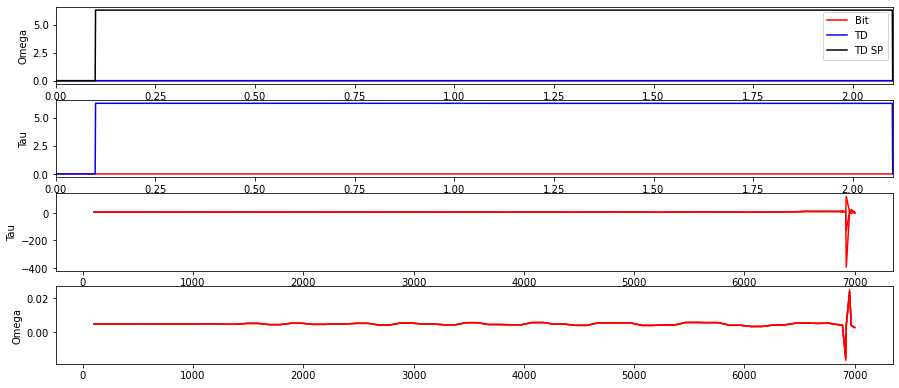

In [8]:
fig = plt.figure(figsize=[15,10])
plt.subplot(6,1,1)
plt.plot(sim.time,sim.omega_bit, 'r')
plt.plot(sim.time,sim.omega_td, 'b')
plt.plot(sim.time,sim.omega_td_sp, 'k')
plt.legend(['Bit', 'TD', 'TD SP'])
plt.ylabel('Omega')
plt.xlim([0, sim.idx*sim.dt])

plt.subplot(6,1,2)
plt.plot(sim.time,sim.tau_bit, 'r')
plt.plot(sim.time,sim.tau_td, 'b')
plt.ylabel('Tau')
plt.xlim([0, sim.idx*sim.dt])

plt.subplot(6,1,3)
plt.plot(bha1.x,sim.tau, 'r')
plt.ylabel('Tau')

plt.subplot(6,1,4)
plt.plot(bha1.x,sim.omega, 'r')
plt.ylabel('Omega')

plt.show()